In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE      = '/content/drive/MyDrive/FraudDetection'
DATA_PATH = os.path.join(BASE, 'data')
PROC_PATH = os.path.join(BASE, 'data', 'processed')
MOD_PATH  = os.path.join(BASE, 'models')
CSV_PATH  = '/content/drive/MyDrive/FraudDetection/dataset/creditcard.csv'

os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs(PROC_PATH, exist_ok=True)
os.makedirs(MOD_PATH,  exist_ok=True)

print('All paths ready!')
print('CSV file exists:', os.path.exists(CSV_PATH))

Mounted at /content/drive
All paths ready!
CSV file exists: True


In [ ]:
# Import all libraries needed for data exploration
import pandas as pd        # for loading and working with tables
import numpy as np         # for numerical calculations
import matplotlib.pyplot as plt   # for drawing charts
import seaborn as sns      # for prettier statistical charts

# Load the dataset from Google Drive
# pd.read_csv reads a CSV file and stores it as a DataFrame
# A DataFrame is like an Excel table in Python
df = pd.read_csv(CSV_PATH)

print('='*50)
print('DATASET OVERVIEW')
print('='*50)
print(f'Total rows:        {len(df):,}')
print(f'Total columns:     {df.shape[1]}')
print(f'Fraud cases:       {df["Class"].sum()}')
print(f'Legitimate cases:  {(df["Class"]==0).sum():,}')
print(f'Fraud rate:        {df["Class"].mean()*100:.4f}%')
print(f'Missing values:    {df.isnull().sum().sum()}')
print('='*50)

# Verify dataset has correct number of rows
# Original dataset must have exactly 284,807 rows and 492 fraud
if len(df) == 284807 and df['Class'].sum() == 492:
    print('DATASET IS CORRECT')
else:
    print('WARNING: Dataset numbers do not match expected')
    print(f'Got {len(df):,} rows and {df["Class"].sum()} fraud')
    print('If fraud rate is around 0.17% you can continue')

df.head()

DATASET OVERVIEW
Total rows:        284,807
Total columns:     31
Fraud cases:       492
Legitimate cases:  284,315
Fraud rate:        0.1727%
Missing values:    0
DATASET IS CORRECT


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
# Compare fraud and legitimate transactions to find patterns
# This helps us understand what makes fraud different from normal transactions

print('--------------------------------------------------')
print('Statistics by Transaction Type')
print('--------------------------------------------------')

# Split the data into two groups
legitimate = df[df['Class'] == 0]
fraud      = df[df['Class'] == 1]

# Show stats for legitimate transactions
print('\nLegitimate Transactions:', len(legitimate))
print('  Average amount: £' + str(round(legitimate['Amount'].mean(), 2)))
print('  Middle amount:  £' + str(round(legitimate['Amount'].median(), 2)))
print('  Highest amount: £' + str(round(legitimate['Amount'].max(), 2)))
print('  Lowest amount:  £' + str(round(legitimate['Amount'].min(), 2)))

# Show stats for fraud transactions
print('\nFraud Transactions:', len(fraud))
print('  Average amount: £' + str(round(fraud['Amount'].mean(), 2)))
print('  Middle amount:  £' + str(round(fraud['Amount'].median(), 2)))
print('  Highest amount: £' + str(round(fraud['Amount'].max(), 2)))
print('  Lowest amount:  £' + str(round(fraud['Amount'].min(), 2)))

# Show the time range of the dataset
print('\nTime Information:')
print('  First transaction at:', int(df['Time'].min()), 'seconds')
print('  Last transaction at: ', int(df['Time'].max()), 'seconds')
print('  Total time covered:  ', round(df['Time'].max() / 3600, 1), 'hours')

# List all column names in the dataset
print('\nAll columns in the dataset:')
for column_name in df.columns:
    print('  -', column_name)

print('--------------------------------------------------')

--------------------------------------------------
Statistics by Transaction Type
--------------------------------------------------

Legitimate Transactions: 284315
  Average amount: £88.29
  Middle amount:  £22.0
  Highest amount: £25691.16
  Lowest amount:  £0.0

Fraud Transactions: 492
  Average amount: £122.21
  Middle amount:  £9.25
  Highest amount: £2125.87
  Lowest amount:  £0.0

Time Information:
  First transaction at: 0 seconds
  Last transaction at:  172792 seconds
  Total time covered:   48.0 hours

All columns in the dataset:
  - Time
  - V1
  - V2
  - V3
  - V4
  - V5
  - V6
  - V7
  - V8
  - V9
  - V10
  - V11
  - V12
  - V13
  - V14
  - V15
  - V16
  - V17
  - V18
  - V19
  - V20
  - V21
  - V22
  - V23
  - V24
  - V25
  - V26
  - V27
  - V28
  - Amount
  - Class
--------------------------------------------------


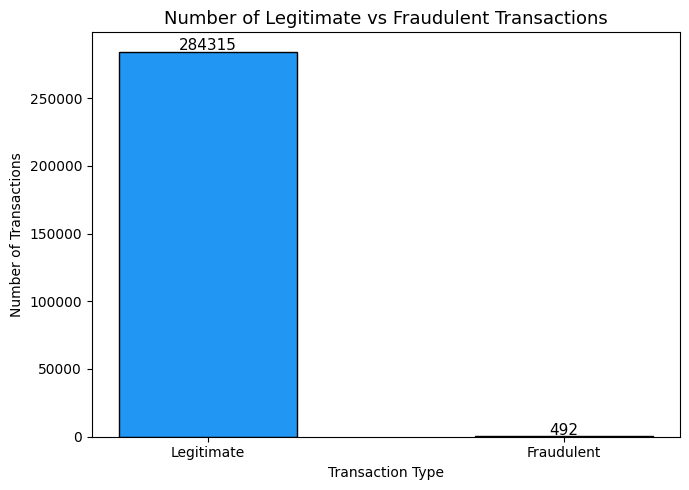

In [ ]:
# Draw a bar chart to show how many legitimate and fraud transactions we have
# This makes it easy to see that fraud is very rare compared to normal transactions

transaction_counts = df['Class'].value_counts()

plt.figure(figsize=(7, 5))

# Blue bar for legitimate transactions, red bar for fraud
bars = plt.bar(
    ['Legitimate', 'Fraudulent'],
    [transaction_counts[0], transaction_counts[1]],
    color=['#2196F3', '#F44336'],
    edgecolor='black',
    width=0.5
)

# Add a title and axis labels
plt.title('Number of Legitimate vs Fraudulent Transactions', fontsize=13)
plt.ylabel('Number of Transactions')
plt.xlabel('Transaction Type')

# Write the exact number on top of each bar so it is easy to read
for i, count in enumerate([transaction_counts[0], transaction_counts[1]]):
    plt.text(
        i,
        count + 1000,
        str(count),
        ha='center',
        fontsize=11
    )

plt.tight_layout()


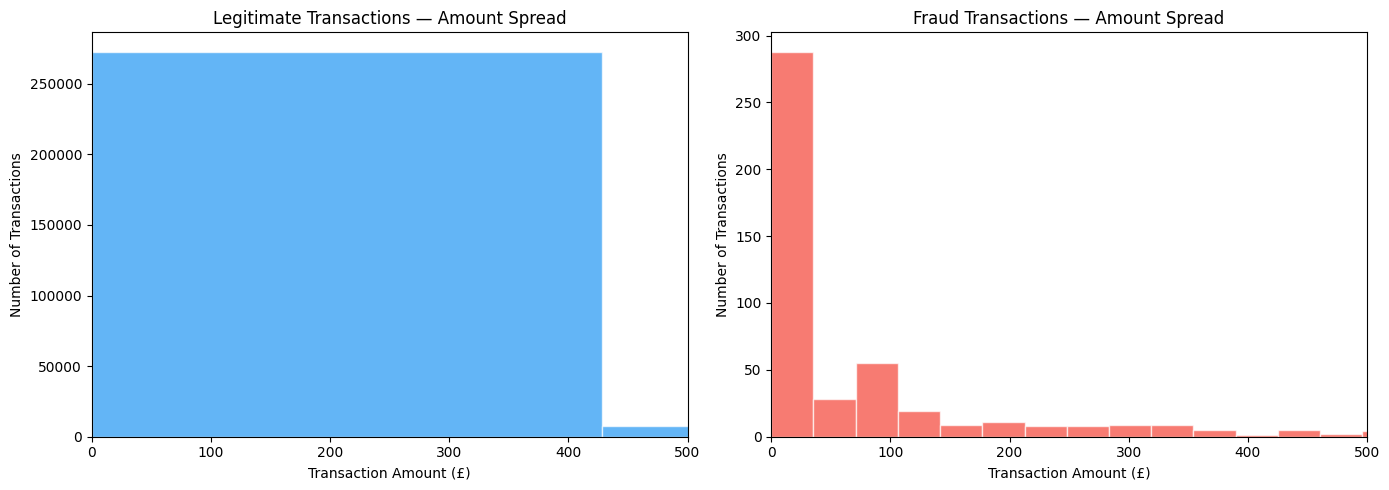

In [ ]:
# Compare how much money was spent in legitimate vs fraud transactions
# We use two side by side charts to make the comparison easy to see
# This helps us understand if fraud tends to happen at certain price ranges

fig, charts = plt.subplots(1, 2, figsize=(14, 5))

# Left chart — shows the spread of amounts for legitimate transactions
# We filter the data to only include rows where Class is 0 (legitimate)
legitimate_amounts = df[df['Class'] == 0]['Amount']

charts[0].hist(
    legitimate_amounts,
    bins=60,
    color='#2196F3',
    alpha=0.7,
    edgecolor='white'
)
charts[0].set_title('Legitimate Transactions — Amount Spread')
charts[0].set_xlabel('Transaction Amount (£)')
charts[0].set_ylabel('Number of Transactions')
charts[0].set_xlim(0, 500)

# Right chart — shows the spread of amounts for fraud transactions
# We filter the data to only include rows where Class is 1 (fraud)
fraud_amounts = df[df['Class'] == 1]['Amount']

charts[1].hist(
    fraud_amounts,
    bins=60,
    color='#F44336',
    alpha=0.7,
    edgecolor='white'
)
charts[1].set_title('Fraud Transactions — Amount Spread')
charts[1].set_xlabel('Transaction Amount (£)')
charts[1].set_ylabel('Number of Transactions')
charts[1].set_xlim(0, 500)

plt.tight_layout()


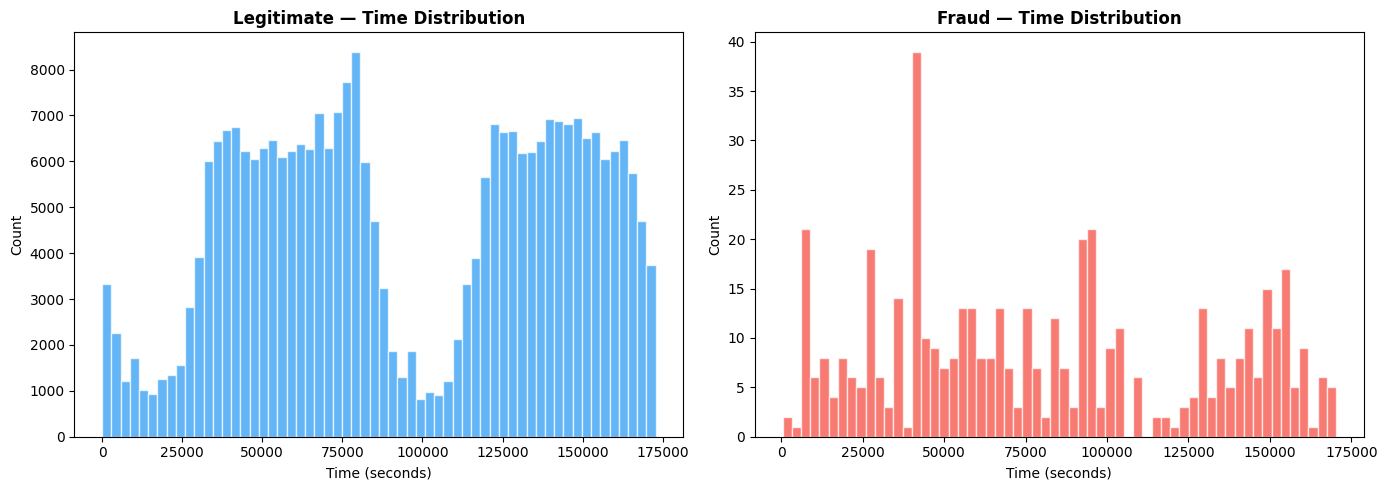

Saved: time_distribution.png


In [ ]:
# Time distribution charts
# Compare when legitimate vs fraud transactions happen
# Time is in seconds since the first transaction

# Reload fresh data to make sure Time column exists
# Time column gets removed during preprocessing
# so we reload here to be safe
df = pd.read_csv(CSV_PATH)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left — when legitimate transactions happen
axes[0].hist(
    df[df['Class']==0]['Time'],
    bins=60,
    color='#2196F3',
    alpha=0.7,
    edgecolor='white'
)
axes[0].set_title('Legitimate — Time Distribution', fontweight='bold')
axes[0].set_xlabel('Time (seconds)')
axes[0].set_ylabel('Count')

# Right — when fraud transactions happen
axes[1].hist(
    df[df['Class']==1]['Time'],
    bins=60,
    color='#F44336',
    alpha=0.7,
    edgecolor='white'
)
axes[1].set_title('Fraud — Time Distribution', fontweight='bold')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'time_distribution.png'), dpi=150)
plt.show()
print('Saved: time_distribution.png')

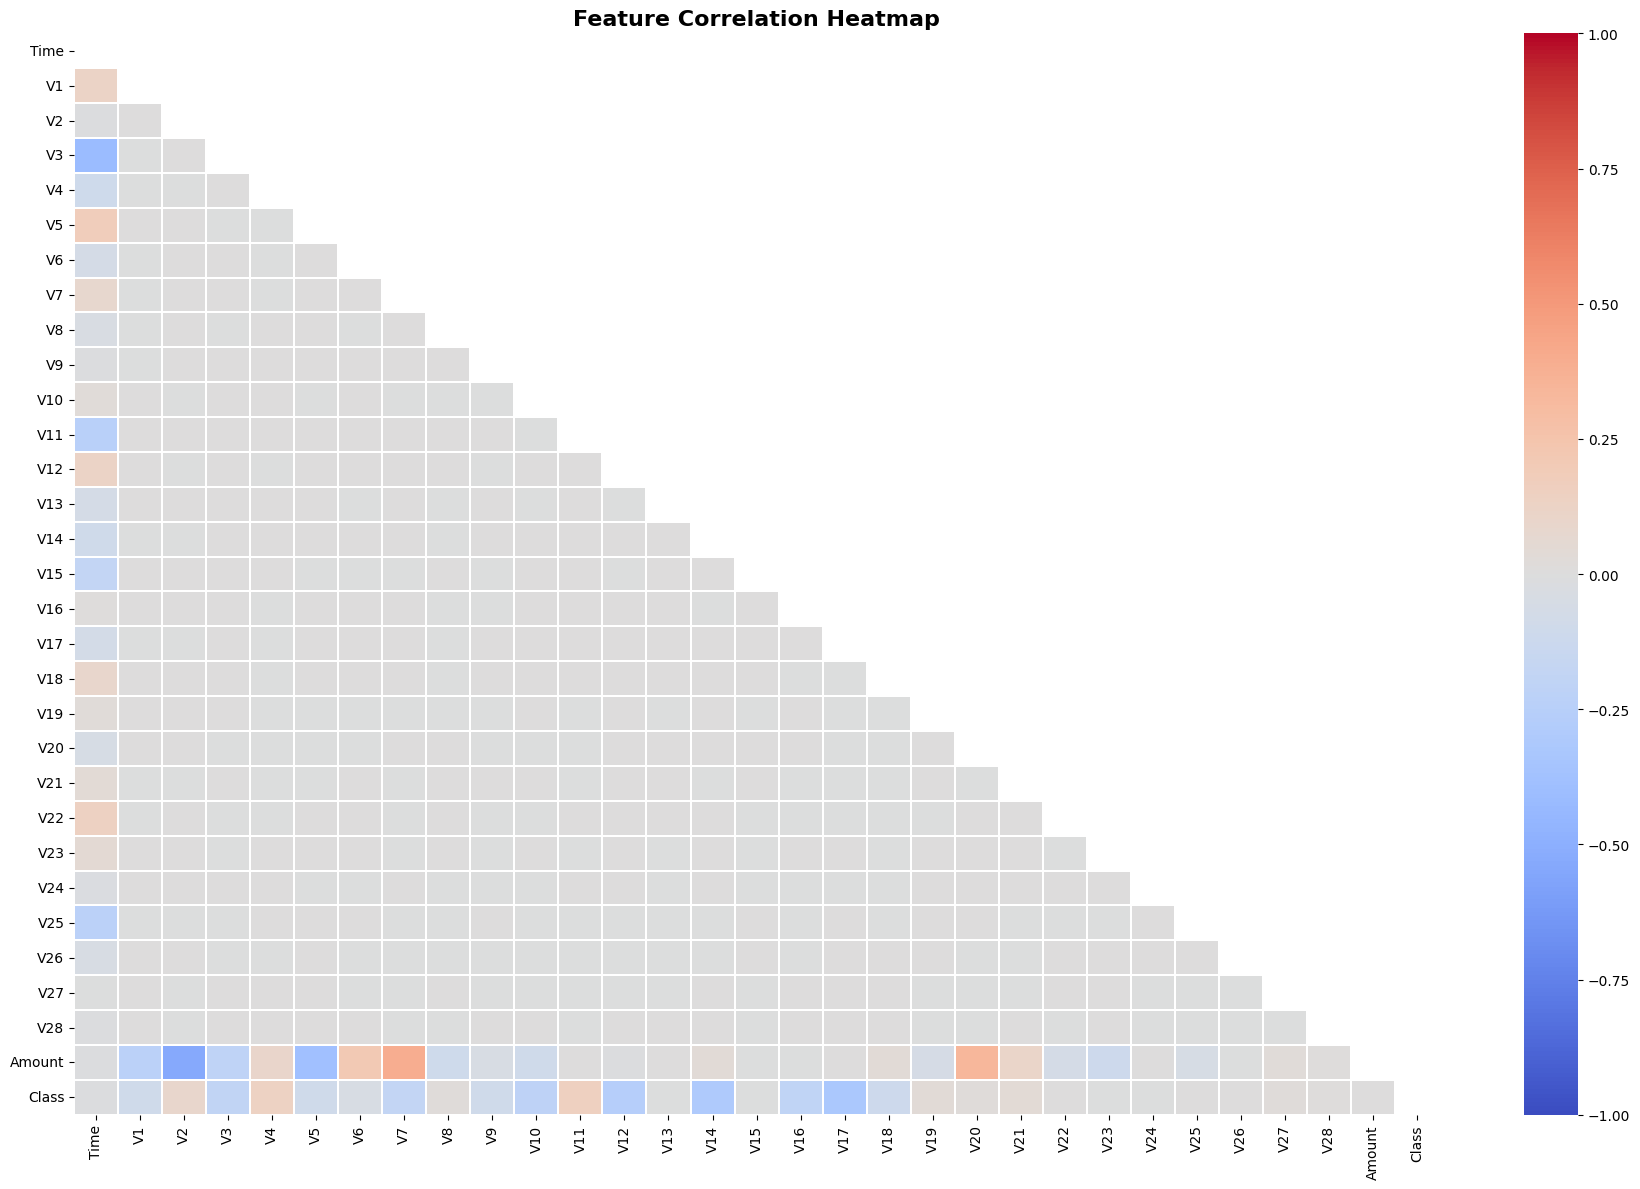

Saved: correlation_heatmap.png


In [ ]:
# Correlation heatmap
# Shows how all 30 features relate to each other
# Helps identify which features are most linked to fraud

# Reload fresh data
df = pd.read_csv(CSV_PATH)

plt.figure(figsize=(18, 12))

# .corr() calculates correlation between every pair of columns
# +1 means features move together
# -1 means they move in opposite directions
#  0 means no relationship
corr = df.corr()

# Hide upper triangle — it is a mirror of lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    cmap='coolwarm',   # blue=negative, red=positive
    center=0,          # white=zero correlation
    annot=False,       # no numbers inside — too crowded
    linewidths=0.3,
    vmin=-1, vmax=1
)

plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'correlation_heatmap.png'), dpi=150)
plt.show()
print('Saved: correlation_heatmap.png')

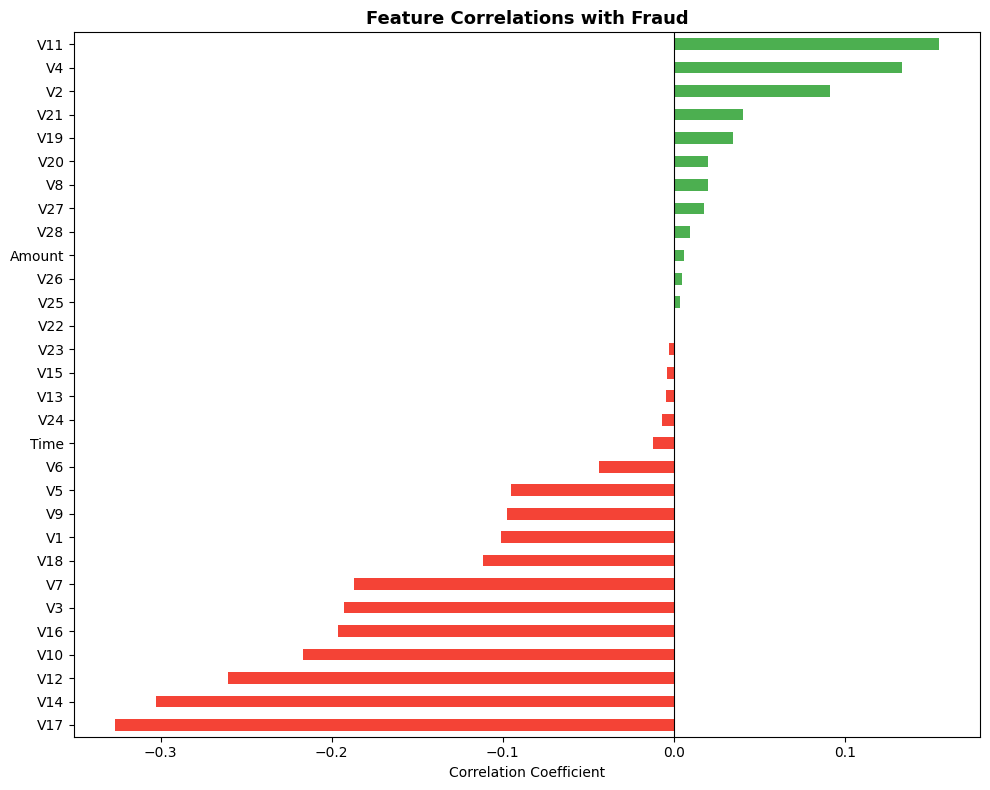

Top 5 features POSITIVELY correlated with fraud:
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876

Top 5 features NEGATIVELY correlated with fraud:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539


In [ ]:
# Feature correlations with fraud chart
# Shows which features most strongly predict fraud

# Reload fresh data
df = pd.read_csv(CSV_PATH)

# Get correlation of each feature with Class
# Drop Class itself — correlation with itself is always 1.0
# Sort from most negative to most positive
corr_fraud = df.corr()['Class'].drop('Class').sort_values()

plt.figure(figsize=(10, 8))

# Red = negative correlation (high value = less fraud)
# Green = positive correlation (high value = more fraud)
colors = ['#F44336' if x < 0 else '#4CAF50' for x in corr_fraud]
corr_fraud.plot(kind='barh', color=colors, figsize=(10, 8))

plt.title('Feature Correlations with Fraud', fontweight='bold', fontsize=13)
plt.xlabel('Correlation Coefficient')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'fraud_correlations.png'), dpi=150)
plt.show()

print('Top 5 features POSITIVELY correlated with fraud:')
print(corr_fraud.tail(5).to_string())
print()
print('Top 5 features NEGATIVELY correlated with fraud:')
print(corr_fraud.head(5).to_string())

/tmp/ipykernel_33718/2577277917.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(
/tmp/ipykernel_33718/2577277917.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(
/tmp/ipykernel_33718/2577277917.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(
/tmp/ipykernel_33718/2577277917.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(
/tmp/ipykernel_33718/2577277917.py:20: MatplotlibDeprecationWarning: The 'labels' parameter 

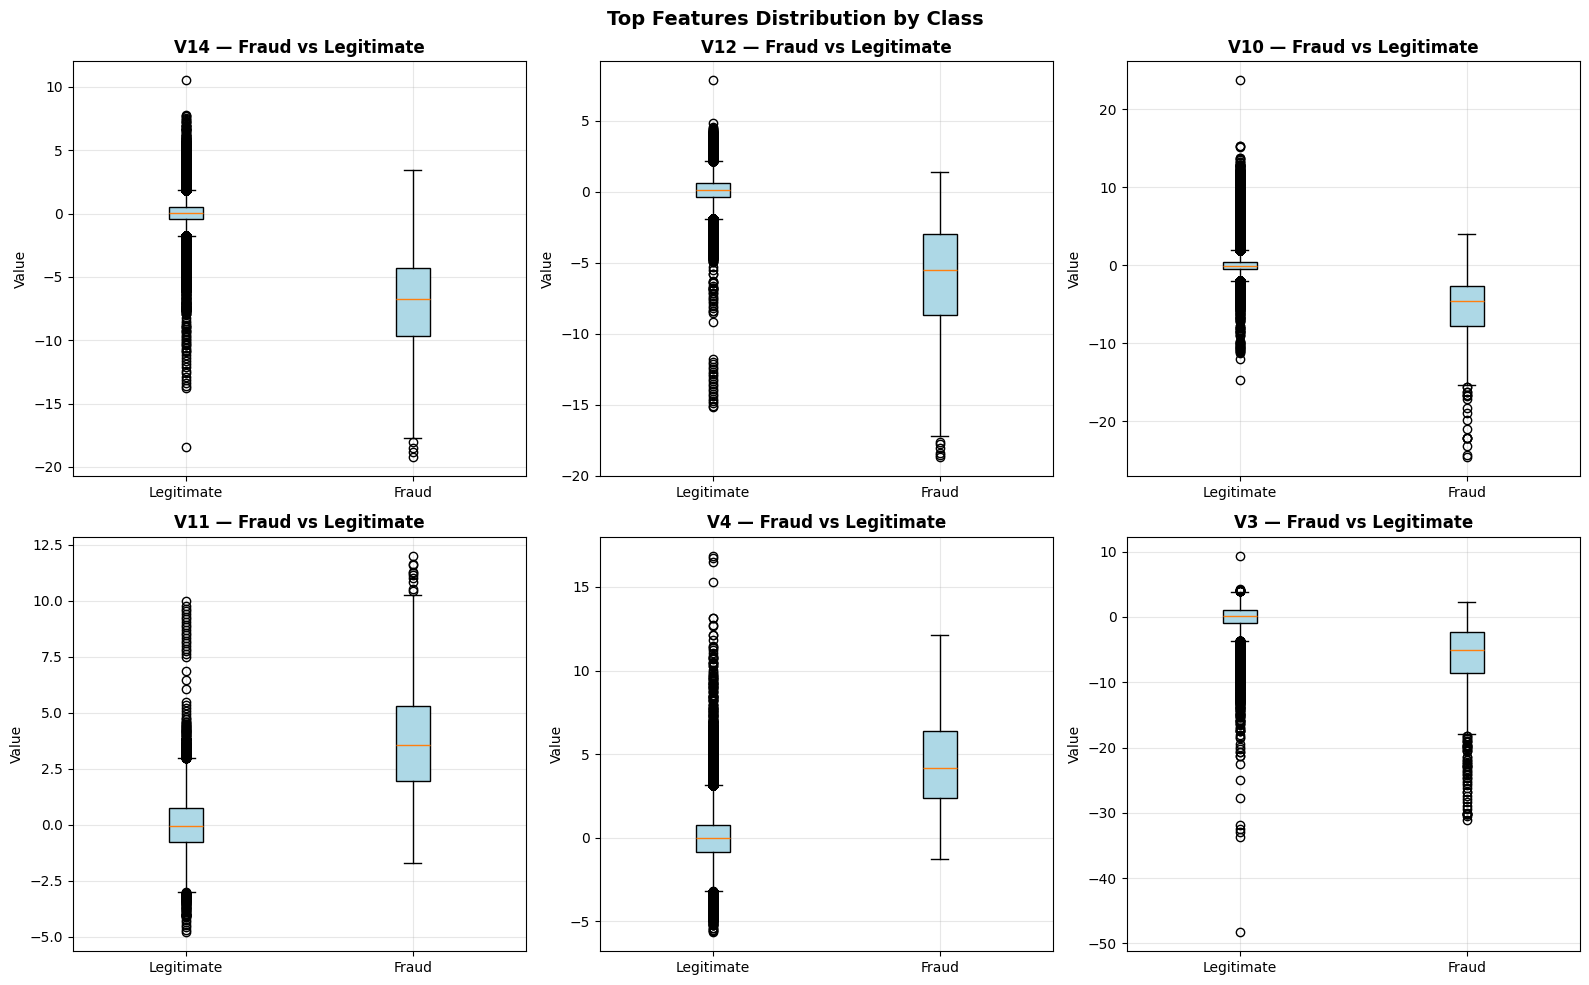

Saved: boxplots.png


In [ ]:
# Box plots for top features
# Compare distributions for fraud vs legitimate transactions
# Shows clearly how the two classes differ for key features

# Reload fresh data
df = pd.read_csv(CSV_PATH)

# Top 6 features by absolute correlation with fraud
top_features = ['V14', 'V12', 'V10', 'V11', 'V4', 'V3']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    # Get values for each class
    data_legit = df[df['Class']==0][feature]
    data_fraud = df[df['Class']==1][feature]

    # Draw box plot for both classes side by side
    axes[i].boxplot(
        [data_legit, data_fraud],
        labels=['Legitimate', 'Fraud'],
        patch_artist=True,
        boxprops=dict(facecolor='lightblue')
    )
    axes[i].set_title(f'{feature} — Fraud vs Legitimate',
                       fontweight='bold')
    axes[i].set_ylabel('Value')
    axes[i].grid(alpha=0.3)

plt.suptitle('Top Features Distribution by Class',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'boxplots.png'), dpi=150)
plt.show()
print('Saved: boxplots.png')

V14, V12, V10 — top row
"For legitimate transactions the box sits near zero. For fraud the box is much lower — around minus 5 to minus 7.
This means when V14, V12 or V10 has a very low value, it is almost certainly fraud. That is why these are the most important features in my model."

"The top row features go DOWN for fraud. The bottom row features go UP for fraud. This pattern is exactly what SHAP confirmed — V14 going low is the biggest signal of fraud in my model."

In [ ]:
# Final summary of key findings from Notebook 1

# Reload fresh data for summary
df = pd.read_csv(CSV_PATH)
corr_fraud = df.corr()['Class'].drop('Class').sort_values()

print('='*60)
print('NOTEBOOK 1 SUMMARY — KEY FINDINGS')
print('='*60)

print(f'\n1. DATASET SIZE')
print(f'   Total transactions: {len(df):,}')
print(f'   Fraud cases:        {df["Class"].sum()} ({df["Class"].mean()*100:.4f}%)')
print(f'   Legitimate cases:   {(df["Class"]==0).sum():,}')

print(f'\n2. CLASS IMBALANCE')
print(f'   Fraud rate is only {df["Class"].mean()*100:.4f}%')
print(f'   SMOTE balancing required in Notebook 2')

print(f'\n3. AMOUNT PATTERNS')
print(f'   Fraud mean amount:  £{df[df["Class"]==1]["Amount"].mean():.2f}')
print(f'   Legit mean amount:  £{df[df["Class"]==0]["Amount"].mean():.2f}')
print(f'   Fraud tends to happen at lower amounts')

print(f'\n4. TOP FEATURES BY CORRELATION WITH FRAUD')
print(f'   Most negative (low value = more fraud):')
for feat, val in corr_fraud.head(5).items():
    print(f'     {feat}: {val:.4f}')
print(f'   Most positive (high value = more fraud):')
for feat, val in corr_fraud.tail(5).items():
    print(f'     {feat}: {val:.4f}')

print(f'\n5. MISSING VALUES')
print(f'   Total missing: {df.isnull().sum().sum()}')
print(f'   No imputation needed')

print()
print('Notebook 1 complete!')
print('Charts saved to:', DATA_PATH)
print('Next: Run Notebook 2')

NOTEBOOK 1 SUMMARY — KEY FINDINGS

1. DATASET SIZE
   Total transactions: 284,807
   Fraud cases:        492 (0.1727%)
   Legitimate cases:   284,315

2. CLASS IMBALANCE
   Fraud rate is only 0.1727%
   SMOTE balancing required in Notebook 2

3. AMOUNT PATTERNS
   Fraud mean amount:  £122.21
   Legit mean amount:  £88.29
   Fraud tends to happen at lower amounts

4. TOP FEATURES BY CORRELATION WITH FRAUD
   Most negative (low value = more fraud):
     V17: -0.3265
     V14: -0.3025
     V12: -0.2606
     V10: -0.2169
     V16: -0.1965
   Most positive (high value = more fraud):
     V19: 0.0348
     V21: 0.0404
     V2: 0.0913
     V4: 0.1334
     V11: 0.1549

5. MISSING VALUES
   Total missing: 0
   No imputation needed

Notebook 1 complete!
Charts saved to: /content/drive/MyDrive/FraudDetection/data
Next: Run Notebook 2


In [ ]:
# Final summary of what we discovered in Notebook 1
# This directly informs decisions made in later notebooks

# Reload fresh data for final summary
df = pd.read_csv(CSV_PATH)
corr_fraud = df.corr()['Class'].drop('Class').sort_values()

print('='*60)
print('NOTEBOOK 1 SUMMARY — KEY FINDINGS')
print('='*60)

print(f'\n1. DATASET SIZE')
print(f'   Total transactions: {len(df):,}')
print(f'   Fraud cases:        {df["Class"].sum()} ({df["Class"].mean()*100:.4f}%)')
print(f'   Legitimate cases:   {(df["Class"]==0).sum():,}')

print(f'\n2. CLASS IMBALANCE')
print(f'   Fraud rate is only {df["Class"].mean()*100:.4f}%')
print(f'   This requires SMOTE balancing in Notebook 2')

print(f'\n3. AMOUNT PATTERNS')
print(f'   Fraud mean amount:  £{df[df["Class"]==1]["Amount"].mean():.2f}')
print(f'   Legit mean amount:  £{df[df["Class"]==0]["Amount"].mean():.2f}')
print(f'   Fraud tends to occur at lower amounts')

print(f'\n4. MOST IMPORTANT FEATURES (by correlation with fraud)')
top5_pos = corr_fraud.tail(5)
top5_neg = corr_fraud.head(5)
print(f'   Positive (increase fraud probability):')
for feat, val in top5_pos.items():
    print(f'     {feat}: {val:.4f}')
print(f'   Negative (decrease fraud probability):')
for feat, val in top5_neg.items():
    print(f'     {feat}: {val:.4f}')

print(f'\n5. MISSING VALUES')
print(f'   Total missing: {df.isnull().sum().sum()}')
print(f'   No missing values — no imputation needed')

print()
print('Notebook 1 complete!')
print('All charts saved to:', DATA_PATH)
print('Next: Run Notebook 2 for preprocessing')

NOTEBOOK 1 SUMMARY — KEY FINDINGS

1. DATASET SIZE
   Total transactions: 284,807
   Fraud cases:        492 (0.1727%)
   Legitimate cases:   284,315

2. CLASS IMBALANCE
   Fraud rate is only 0.1727%
   This requires SMOTE balancing in Notebook 2

3. AMOUNT PATTERNS
   Fraud mean amount:  £122.21
   Legit mean amount:  £88.29
   Fraud tends to occur at lower amounts

4. MOST IMPORTANT FEATURES (by correlation with fraud)
   Positive (increase fraud probability):
     V19: 0.0348
     V21: 0.0404
     V2: 0.0913
     V4: 0.1334
     V11: 0.1549
   Negative (decrease fraud probability):
     V17: -0.3265
     V14: -0.3025
     V12: -0.2606
     V10: -0.2169
     V16: -0.1965

5. MISSING VALUES
   Total missing: 0
   No missing values — no imputation needed

Notebook 1 complete!
All charts saved to: /content/drive/MyDrive/FraudDetection/data
Next: Run Notebook 2 for preprocessing
